In [28]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [29]:
rfm = pd.read_csv("rfm_data.csv")
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [30]:
rfm.info()

<class 'pandas.DataFrame'>
RangeIndex: 4338 entries, 0 to 4337
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CustomerID  4338 non-null   float64
 1   Recency     4338 non-null   int64  
 2   Frequency   4338 non-null   int64  
 3   Monetary    4338 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 135.7 KB


In [31]:
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


In [32]:
X = rfm[["Recency", "Frequency","Monetary"]]
X.head()

,Recency,Frequency,Monetary
0,326,1,77183.60
1,2,7,4310.00
2,75,4,1797.24
3,19,1,1757.55
4,310,1,334.40


In [33]:
#Normalize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[ 2.33457414, -0.4250965 ,  8.36301037],
       [-0.90534032,  0.3544168 ,  0.2516989 ],
       [-0.17535959, -0.03533985, -0.02798783],
       [-0.73534481, -0.4250965 , -0.03240559],
       [ 2.17457836, -0.4250965 , -0.19081155]])

In [34]:
inertia = []
for k in range(1,11):
    model = KMeans(n_clusters=k, random_state=42,n_init= 10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

<function matplotlib.pyplot.show(close=None, block=None)>

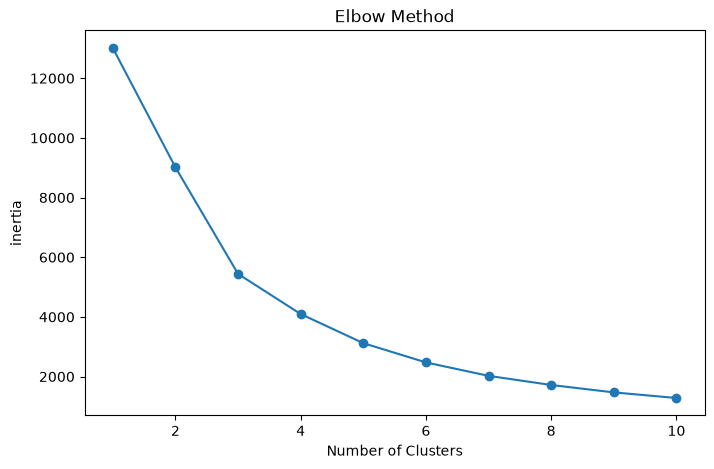

In [35]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11),inertia,marker ="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("inertia")
plt.show

In [36]:
#Kmeans model
kmeans = KMeans(n_clusters=4, random_state=42,n_init =10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,3
1,12347.0,2,7,4310.00,0
2,12348.0,75,4,1797.24,0
3,12349.0,19,1,1757.55,0
4,12350.0,310,1,334.40,1


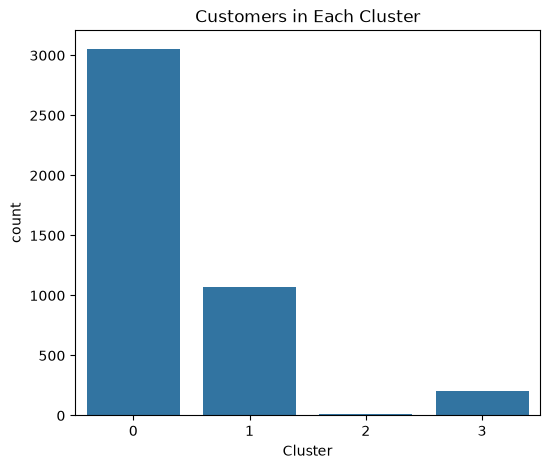

In [37]:
#cluster distribution
plt.figure(figsize=(6,5))
sns.countplot(data = rfm,x= "Cluster")
plt.title("Customers in Each Cluster")
plt.show()

In [38]:
cluster_summary = (rfm.groupby("CustomerSegment")[["Recency","Frequency","Monetary"]].mean())
cluster_summary

KeyError: 'CustomerSegment'

In [ ]:
cluster_names = {
    0: "Regular",
    1: "At-Risk",
    2: "VIP",
    3: "Loyal"
}

rfm["CustomerSegment"] = rfm["Cluster"].map(cluster_names)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,CustomerSegment
0,12346.0,326,1,77183.60,3,Loyal
1,12347.0,2,7,4310.00,0,Regular
2,12348.0,75,4,1797.24,0,Regular
3,12349.0,19,1,1757.55,0,Regular
4,12350.0,310,1,334.40,1,At-Risk


In [ ]:
rfm["CustomerSegment"].value_counts()

CustomerSegment
Regular    3054
At-Risk    1067
Loyal       204
VIP          13
Name: count, dtype: int64

In [ ]:
rfm.to_csv("customer_segments.csv", index=False)
print("Customer Segmentation Completed Successfully!")

Customer Segmentation Completed Successfully!
